In [1]:
import numpy as np
import numba as nb
import scipy.stats as stats
import torch
import matplotlib.pyplot as plt
import pickle
import yaml
from sbi.utils.sbiutils import gradient_ascent

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.utils.user_input_checks import process_simulator
from sbi.inference.posteriors import DirectPosterior

/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from functools import partial
import sys
sys.path.append('../src')

from simulator import smFRET_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config
from utils import eval_spline_from_config

In [3]:
data_cfg = "../conf/simulator/highnodes.yaml"

In [4]:
prior = generate_posterior_prior_from_config(data_cfg, device="cpu")
eval_spline = eval_spline_from_config(data_cfg)

In [5]:
samples = prior.sample((10000,))

/tmp/ipykernel_2036761/2780709731.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=13)


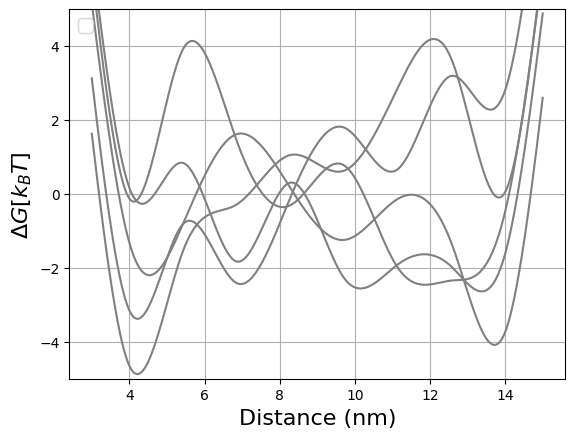

In [9]:
samples = prior.sample((10,))
for i in range(5):
    x, y = eval_spline(
        params=samples[i],
        x_eval=np.linspace(3, 15, 1000),
    )
    plt.plot(x, y, color='gray', alpha=1)
plt.xlabel("Distance (nm)", fontsize=16)
plt.ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
plt.ylim(-5, 5)
plt.grid()
plt.legend(fontsize=13)